Lab 8 — Naive Bayes: Rice Classification

Names: Joonsuh Kim, William Roberts

Dataset: UCI Rice (Cammeo and Osmancik)
Source: https://archive.ics.uci.edu/dataset/545/rice-cammeo-and-osmancik

Algorithm: Gaussian Naive Bayes (GaussianNB)

Question:
Can we predict a rice grain's variety using its size and shape measurements?

Dataset description:
The dataset contains 3,810 rice grains from two varieties:
Cammeo and Osmancik. Each grain has seven numerical measurements.

Input features:
Area, Perimeter, Major_Axis_Length, Minor_Axis_Length,
Eccentricity, Convex_Area, and Extent.

Target:
Class — Cammeo or Osmancik.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Loading and Checking the Data

I loaded the rice dataset and checked its size, missing values,
and the number of samples in each variety.

In [2]:
# Read the uploaded ARFF file.
data, metadata = arff.loadarff("Rice_Cammeo_Osmancik.arff")

# Convert the data into a table.
df = pd.DataFrame(data)

# Convert the class names from bytes into text.
df["Class"] = df["Class"].str.decode("utf-8")

# Inspect the dataset.
display(df.head())

print("Rows and columns:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSamples in each variety:")
print(df["Class"].value_counts())

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


Rows and columns: (3810, 8)

Missing values:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64

Samples in each variety:
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64


Data Preparation

I checked for missing values and removed incomplete rows if needed.
The seven measurements were used as input features, and Class
was used as the target.

The features are already numerical, so categorical encoding
is not needed.

In [3]:
# Remove incomplete rows, if any.
before = len(df)
df = df.dropna().copy()

print("Rows removed:", before - len(df))

# Separate the input features and target.
X = df.drop(columns=["Class"])
y = df["Class"]

print("Input features:", X.columns.tolist())
print("Number of features:", X.shape[1])

Rows removed: 0
Input features: ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
Number of features: 7


Training and Test Sets

I used 80% of the data for training and 20% for testing.
Stratification keeps the proportions of the two varieties
similar in both sets.

The test data is kept separate to evaluate predictions
on samples not used for training.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 3048
Test samples: 762


Training samples: 3048
Test samples: 762

Gaussian Naive Bayes Model

I used Gaussian Naive Bayes because the input features are
numerical measurements. The model assumes a normal distribution
for each feature within each variety and assumes conditional
independence between features.

In [6]:
# Create the model.
model = GaussianNB()

# Learn from the training measurements and labels.
model.fit(X_train, y_train)

# Predict the varieties of the test samples.
y_pred = model.predict(X_test)

Evaluation

I compared the predictions with the actual test labels.
Accuracy shows the percentage of correct predictions.
The classification report and confusion matrix show
how well the model recognized each variety.

In [7]:
# Calculate the proportion of correct predictions.
accuracy = accuracy_score(y_test, y_pred)

correct = (y_test.to_numpy() == y_pred).sum()
incorrect = len(y_test) - correct

print(f"Test accuracy: {accuracy:.2%}")
print(f"Correct predictions: {correct} out of {len(y_test)}")
print(f"Incorrect predictions: {incorrect}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 89.11%
Correct predictions: 679 out of 762
Incorrect predictions: 83

Classification report:
              precision    recall  f1-score   support

      Cammeo       0.90      0.84      0.87       326
    Osmancik       0.88      0.93      0.91       436

    accuracy                           0.89       762
   macro avg       0.89      0.88      0.89       762
weighted avg       0.89      0.89      0.89       762



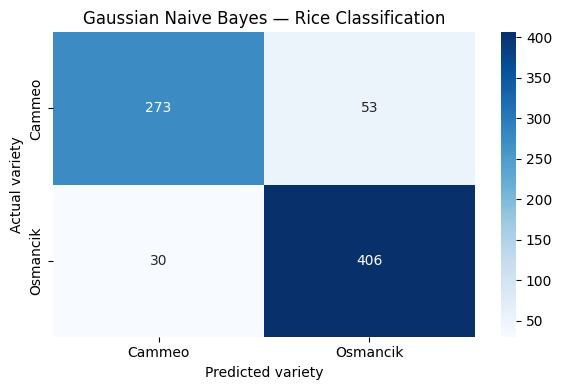

In [8]:
# Use the same class order for rows and columns.
labels = model.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted variety")
plt.ylabel("Actual variety")
plt.title("Gaussian Naive Bayes — Rice Classification")
plt.tight_layout()
plt.show()

Summary

We used Gaussian Naive Bayes to predict rice varieties from seven
size and shape measurements. After an 80/20 train-test split,
the model correctly classified 679 of 762 test samples (89.11%).
It recognized Osmancik more successfully than Cammeo. These
measurements helped distinguish the varieties, but 83 samples
were misclassified, so the predictions are not always correct.